# G2 - Preliminary sizing: thin and thick shells

**057922 Nuclear Design and Technology** · Project Lab

Author: Giovanni Zullo

---

## In this notebook

Two neutral cylinders under internal pressure, one thin, one thick. You compute them by
hand, run them in z3st, and find out where the thin-shell formula stops being good enough.

Then you apply the same procedure to *your own* Project Lab vessel and produce a
**tentative** wall thickness. Tentative is the word the Code itself uses, NB-3324.1, and here it is literal: the **allowable** you size against
is read at a design temperature you cannot know until G4 gives you the temperature field.

> The data here are **not** the Project Lab data: adapt them. This notebook helps you with item 3 of Part 1.


---
## Step 0: Environment

The same cells as in every notebook of the Project Lab. They install FEniCSx and z3st, pinned so that everyone has the
same environment. Two to four minutes the first time; re-running it later
is fast because it detects what is already there.


In [1]:
# --- where is the course material? (Colab only; a no-op on your own machine) -------
# Nothing to configure. Three places are tried, in the order that costs least:
#   1. already on disk next to this notebook  -> nothing to do
#   2. fetchable from GitHub                  -> the next cell downloads it
#   3. neither                                -> mount Google Drive and look there
# Drive is the LAST resort on purpose: when the course repository is public, step 2
# succeeds and nobody is ever asked to authorise Drive. When it is not -- a private
# repo, or no network -- step 3 is exactly what is needed, so it happens by itself.
import os, glob, urllib.request

URL = ('https://raw.githubusercontent.com/giozu/ndt-labs/'
       'main/launcher/ndt_setup.py')

def _on_colab():
    try:
        import google.colab  # noqa: F401
        return True
    except ImportError:
        return False

def _find_labs(start=None):
    # The course folder above us, or None. Same walk-up the bootstrap uses.
    d = os.path.abspath(start or os.getcwd())
    while True:
        if os.path.isfile(os.path.join(d, 'launcher', 'ndt_setup.py')):
            return d
        parent = os.path.dirname(d)
        if parent == d:
            return None
        d = parent

def _github_has_it():
    try:
        req = urllib.request.Request(URL, method='HEAD')
        with urllib.request.urlopen(req, timeout=8) as r:
            return r.status == 200
    except Exception:
        return False

def _search_drive():
    # The obvious place first -- the course folder uploaded to the top of My Drive --
    # then one or two folders down, in case it was tidied away. NOT a deep recursive
    # hunt: if it is not within reach of these, the problem is not the depth.
    D = '/content/drive/MyDrive'
    for pat in (f'{D}/ndt-labs/launcher/ndt_setup.py',
                f'{D}/*/launcher/ndt_setup.py',
                f'{D}/*/*/launcher/ndt_setup.py'):
        hits = glob.glob(pat)
        if hits:
            return hits[0]
    return None


if not _on_colab():
    print('[where] local machine - the files are already here')
elif _find_labs():
    print('[where] already here:', _find_labs())
elif _github_has_it():
    print('[where] will be downloaded from GitHub by the next cell')
else:
    print('[where] not on disk and not reachable on GitHub - looking on Google Drive')
    from google.colab import drive
    drive.mount('/content/drive')

    # A mount can succeed and still show NOTHING: a stale mount left by an earlier
    # attempt, or the wrong Google account. That looked exactly like "the folder is
    # somewhere unexpected" once, and sent the search deeper and deeper for nothing.
    # Distinguish the two, because the remedies have nothing in common.
    top = glob.glob('/content/drive/MyDrive/*')
    if not top:
        raise SystemExit(
            'Google Drive is mounted but MyDrive looks EMPTY.\n'
            'That is a mount problem, not a missing folder. Either an earlier mount is\n'
            'stale, or you authorised a different Google account. Fix it with:\n'
            "    drive.mount('/content/drive', force_remount=True)\n"
            'and pick the account that holds the course folder. If it stays empty,\n'
            'Runtime -> Disconnect and delete runtime, then start again.')

    hit = _search_drive()
    if not hit:
        raise SystemExit(
            'Your Drive is readable but no launcher/ndt_setup.py was found in it.\n'
            'Top level of MyDrive:\n  ' + '\n  '.join(sorted(top)[:20]) + '\n'
            'Upload the course folder there, or os.chdir() into it by hand.')

    # The repository ROOT is enough: everything downstream walks up from the working
    # directory, so there is no per-notebook path to keep in sync here.
    os.chdir(os.path.dirname(os.path.dirname(hit)))
    print('[where] found on Drive:', os.getcwd())

print('cwd      :', os.getcwd())

[where] local machine - the files are already here
cwd      : ~/ndt-labs/sessions/G02_shells


In [2]:
import os, sys, subprocess

# Get the shared bootstrap, ndt_setup.py. Two ways, and the notebook picks one:
#  - LOCAL: you cloned ndt-labs, so launcher/ndt_setup.py is already on disk a few
#    directories up. Use that copy -- no network, and any pin you edit takes effect.
#  - COLAB: fetch it. Check the file is NON-EMPTY: wget -O creates
#    a zero-byte file when the download fails, that file "exists", the download is then
#    skipped forever, and `import ndt_setup` silently imports nothing.
URL = ('https://raw.githubusercontent.com/giozu/ndt-labs/'
       'main/launcher/ndt_setup.py')

def _find_launcher(d=None):
    d = os.path.abspath(d or os.getcwd())
    while True:
        p = os.path.join(d, 'launcher', 'ndt_setup.py')
        if os.path.isfile(p) and os.path.getsize(p) > 0:
            return os.path.dirname(p)
        parent = os.path.dirname(d)
        if parent == d:
            return None
        d = parent

launcher = _find_launcher()
if launcher is None:
    if not os.path.exists('ndt_setup.py') or os.path.getsize('ndt_setup.py') == 0:
        subprocess.run(['wget', '-q', URL, '-O', 'ndt_setup.py'])
    if not os.path.exists('ndt_setup.py') or os.path.getsize('ndt_setup.py') == 0:
        raise SystemExit('bootstrap download failed (0 bytes). Check network access '
                         'to the course repository, then re-run this cell.')
    launcher = os.getcwd()
sys.path.insert(0, launcher)

import ndt_setup
ndt_setup.setup()

[ndt] local environment detected -- nothing will be installed
  python   ~/miniconda3/envs/z3st/bin/python3.12


  z3st at  ~/z3st
  labs at  ~/ndt-labs

--- environment check ---


  dolfinx  0.11.0
  numpy    2.4.6
  gmsh     4.15.2


  z3st     0.3.2   [course-2627.1]
  MPI      Open MPI v5.0.10, package: Open MPI conda@9ee00b64ad27 

ENVIRONMENT OK


True

---
## 1. Two formulas, and the question of which to use

### Mariotte: the thin shell

If the wall is thin, assume the hoop stress is **uniform** across it. Equilibrium of a half-ring of unit height (the pressure acts on the inner diameter $2a$, the wall resists on two cuts of thickness $t$) then gives

$$\sigma_\theta = \frac{p\ a}{t}, \qquad \sigma_z = \frac{p\ a}{2t}, \qquad \sigma_r = -\frac{p}{2} $$

with $a$ the inner radius, $b$ the outer one and $t = b - a$ the wall thickness, the same symbols as Lamé below. $\sigma_r = -p/2$ is the average of a radial stress that goes from $-p$ at the bore to $0$ outside.

The factor 2 between hoop and axial is why **a sausage splits lengthwise**, and why a closed vessel is governed by its hoop stress.

### Lamé: the thick shell

Drop the assumption. Solving equilibrium + compatibility + Hooke in cylindrical
coordinates gives, for internal pressure $p$ on $a$ and nothing outside,

$$\sigma_r(r) = \frac{p\ a^2}{b^2-a^2}\left(1 - \frac{b^2}{r^2}\right),
\qquad
\sigma_\theta(r) = \frac{p\ a^2}{b^2-a^2}\left(1 + \frac{b^2}{r^2}\right).$$

Note what this says that Mariotte cannot: $\sigma_\theta$ is **not uniform**, it is
largest at the inner wall, and $\sigma_r$ goes from $-p$ inside to $0$
outside. Note also that $\sigma_\theta - \sigma_r$, the Tresca stress intensity, is
largest at the bore. That is where a thick cylinder yields first.

### And the Code: NB-3324.1

ASME III gives the **tentative** thickness of a cylindrical shell under internal pressure
directly, in **NB-3324.1**:

$$t = \frac{P\ R}{S_m - 0.5\ P}\qquad (R = \text{inner radius})$$

with $P$ the design pressure and $S_m$ the design stress intensity, the allowable.

With a liner, **NB-3122.2** fixes where the diameters are taken: for internal pressure, $R$ at
the inner face of the liner (a); for external pressure, the outside diameter at the outer face
of the vessel (b). The liner itself is given no strength (NB-3122.1): $t$ is the vessel alone.

It is not a third theory. The Code's $R$ is the $a$ of Mariotte. Form the Tresca membrane
stress intensity from the two Mariotte averages,
$P_m = \sigma_\theta - \sigma_r = P\ a/t + P/2$, and set $P_m = S_m$: that gives
$t\ (S_m - P/2) = P\ a$, which is the formula. The $0.5\ P$ in it is the radial stress.

### Where these live outside a reactor

| | |
|---|---|
| **Arch dam** | The hoop formula is the historical preliminary-sizing method, but in **compression**, which is the whole reason arch dams exist: concrete takes no tension. Pressure grows with depth, so each ring is sized separately and the wall thickens downward. A dam has no end caps, so the water pressure produces no axial force: $\sigma_z \approx 0$, and the hoop stress is not twice an axial one as in a closed vessel. |
| **Water tank** | The cleanest $p = \rho g h$ example: thicker at the bottom, for the same reason. |
| **Gun barrel** | Lamé's 1852 problem, born for artillery. Autofrettage, deliberately yielding the bore to leave favourable residual stresses, is the direct descendant. |
| **Penstock** | The wall thickens along the run as the head grows: the same thin-shell sizing, ring by ring. |

In [3]:
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams.update({'figure.figsize': (11, 4.2), 'axes.grid': True, 'grid.alpha': 0.3, 'font.size': 11})

def lame(r, a, b, p):
    """Thick cylinder, internal pressure p, free outside. Returns sigma_r, sigma_theta.

    Exact solution: sigma_theta(r) is the true stress at each radius, peaking at
    r=a. Its average ALONG r reproduces pa/t exactly (mariotte()),
    but the pointwise profile is not uniform, while Mariotte assumes it is.
    """
    
    A = p*a**2/(b**2 - a**2)
    return A*(1 - b**2/r**2), A*(1 + b**2/r**2)

def mariotte(a, b, p):
    """Thin shell, from equilibrium of a half-ring: hoop p a/t, axial p a/(2t),
    with a the inner radius. The hoop value is the exact through-wall average of
    the Lame hoop stress (§4); what Mariotte gets wrong is the profile."""
    t = b - a
    return p*a/t, p*a/(2*t)          # hoop, axial

print('sanity checks against limits we know:')

a, b, p = 0.02, 0.03, 1.0e6                 # (m, m, Pa)
sr, st = lame(np.array([a, b]), a, b, p)    # (Pa, Pa)

print(f'  Lame sigma_r at the bore  = {sr[0]/1e6:+7.3f} MPa')
print(f'  Lame sigma_r outside      = {sr[1]/1e6:+7.3f} MPa')
print(f'  Lame sigma_theta - sigma_r at bore = {(st[0]-sr[0])/1e6:.3f} MPa'
      f'  vs outside {(st[1]-sr[1])/1e6:.3f} MPa  -> yields at the bore')


sanity checks against limits we know:
  Lame sigma_r at the bore  =  -1.000 MPa
  Lame sigma_r outside      =  +0.000 MPa
  Lame sigma_theta - sigma_r at bore = 3.600 MPa  vs outside 1.600 MPa  -> yields at the bore


A neutral vessel, sized with this formula: $D_i$ = 0.6 m, $P$ = 6 MPa, the neutral steel at a tentative 290°C.


In [4]:
# >>> CHANGE HERE: NB-3324.1 on a neutral vessel; replace the numbers with yours
# The neutral steel of these notebooks (its table is in G4, section 4), read at a tentative
# design temperature of 290 degC, which falls in the row 300 of that table.
Sy_T, Su = 201e6, 414e6            # Pa   yield and ultimate strength: the two you are GIVEN
Sm = min(Su/3, 2*Sy_T/3)           # Pa   the allowable is derived: ASME II-D Mandatory Appendix 2, para 2-110
Di, P_int = 0.600, 6.0e6           # m, Pa   inner diameter, design internal pressure

t_int = P_int*(Di/2)/(Sm - 0.5*P_int)
print(f"Sm = {Sm/1e6:.1f} MPa, {'Su/3' if Su/3 <= 2*Sy_T/3 else '2Sy/3'} governing")
print(f'internal pressure {P_int/1e6:.1f} MPa  ->  t = {t_int*1e3:.2f} mm')


Sm = 134.0 MPa, 2Sy/3 governing
internal pressure 6.0 MPa  ->  t = 13.74 mm


---
## 2. The thin cylinder: does Mariotte hold?

Geometry: $R_i = a = 2.40$ m, $R_o = b = 2.50$ m, so $t/a = 0.042$ (the thin-shell limit textbooks usually set is $t/a < 1/10$).
Internal pressure: $p = 1$ MPa, with the end-cap load applied on top.

Run it. The case prints its own comparison against both closed forms and finishes with **PASS** or **FAIL**: that is your self-check.

In [5]:
# This cell loads two verification cases that are available in the z3st repository
# https://github.com/giozu/z3st/tree/main/z3st/cases/verification/mechanics/mariotte_thin_shell 
# https://github.com/giozu/z3st/tree/main/z3st/cases/verification/mechanics/lame_gps_2D
# P.s., the links point to the "main" branch, they are the same in the "course" branch.

CASES = ndt_setup.z3st_cases('verification', 'mechanics')

THIN  = os.path.join(CASES, 'mariotte_thin_shell')
THICK = os.path.join(CASES, 'lame_gps_2D')

ndt_setup.run_case(THIN, mesh_dim='-2') # execution of the THIN (mariotte_thin_shell) case
print('results in:', os.path.join(THIN, 'output'))


$ gmsh mesh.geo -2 -o mesh.msh


Info    : Running '~/miniconda3/envs/z3st/bin/gmsh mesh.geo -2 -o mesh.msh' [Gmsh 4.15.2, 1 node, max. 1 thread]
Info    : Started on Mon Nov  9 10:14:46 2026
Info    : Reading 'mesh.geo'...
Info    : Done reading 'mesh.geo'
Info    : Meshing 1D...
Info    : [  0%] Meshing curve 1 (Line)
Info    : [ 30%] Meshing curve 2 (Line)
Info    : [ 60%] Meshing curve 3 (Line)
Info    : [ 80%] Meshing curve 4 (Line)
Info    : Done meshing 1D (Wall 0.000238218s, CPU 6.9e-05s)
Info    : Meshing 2D...
Info    : Meshing surface 1 (Transfinite)
Info    : Done meshing 2D (Wall 0.00120545s, CPU 0.000346s)
Info    : 3321 nodes 3444 elements
Info    : Writing 'mesh.msh'...
Info    : Done writing 'mesh.msh'
Info    : Stopped on Mon Nov  9 10:14:46 2026 (From start: Wall 0.0102105s, CPU 0.407854s)

$ ~/miniconda3/envs/z3st/bin/python3.12 -m z3st


p 01/1: t = 0.00e+00 s | LHR = 0.00e+00 W/m

[UPDATING q_third]
  → dt=0: solving static step / initial condition
Computing symbolic result fields (strain, stress, ...)



***


### spine - solve


***



Current step = 0 | dt = 0.00e+00 s
  → Max iterations              : 100
  → Staggering tolerance |ΔT|   : 1.0e-06
  → Staggering tolerance |Δu|   : 1.0e-06
  → Staggering tolerance |ΔD|   : 1.0e-04
  → Relative tolerance th       : 1.0e-06
  → Relative tolerance mech     : 1.0e-06
  → Relative tolerance dmg      : 1.0e-06


#### Iteration 1/100


**[INFO]** Assembling thermal problem...

  Building weak form, volume integrals (dx) for steel, tag = 10
  → q_third[steel](W/m3) min = 0.00e+00, max = 0.00e+00, mean = 0.00e+00
  T_new: min=300.00 K, max=300.00 K, mean=300.00 K
  ||ΔT||/||T|| = 3.569e-14
  [adaptive] relax_T=0.90

**[INFO]** Assembling mechanical problem...
  **[INFO]** Updating Displacement Dirichlet on region 3 → 0.0
  **[INFO]** Updating traction on region 4 → 12250000.

[INFO] Reading VTU file: ~/z3st/z3st/cases/verification/mechanics/mariotte_thin_shell/output/fields.vtu

[AVAILABLE FIELDS]
  Point data:
     1) Temperature                    shape=(3321,)
     2) Displacement                   shape=(3321, 2)
     3) Strain (points)                shape=(3321, 9)
     4) Stress (points)                shape=(3321, 9)
     5) VonMises (points)              shape=(3321,)
     6) Hydrostatic (points)           shape=(3321,)
     7) StrainEnergyDensity (points)   shape=(3321,)

  Cell data:
     1) MaterialID                     shape=(3200,)
     2) Strain (cells)                 shape=(3200, 9)
     3) Stress (cells)                 shape=(3200, 9)
     4) VonMises (cells)               shape=(3200,)
     5) Hydrostatic (cells)            shape=(3200,)
     6) StrainEnergyDensity (cells)    shape=(3200,)
     7) HeatFlux (cells)               shape=(3200, 3)

[INFO] Grid bounds:
	x ∈ [2.4000e+00, 2.5000e+00]
	y ∈ [0.0000e+00, 1.5000e+01]
	z ∈ [0.0000e

In [6]:
import pyvista as pv

def radial_profile(case_dir, band=0.02):
    """Stress components along a radius at mid-height. 
    Component order is
    0 = rr, 
    4 = theta-theta, 
    8 = zz"""

    m = pv.read(os.path.join(case_dir, 'output', 'fields.vtu'))
    pts, S = m.points, m.point_data['Stress (points)']
    z = pts[:, 1]
    sel = np.abs(z - 0.5*(z.min() + z.max())) < band*(z.max() - z.min())
    r = pts[sel, 0]; S = S[sel]
    r_u, idx = np.unique(np.round(r, 9), return_index=True)
    return r_u, S[idx, 0], S[idx, 4], S[idx, 8]

r, s_rr, s_tt, s_zz = radial_profile(THIN)
a_t, b_t, p_t = r.min(), r.max(), 1.0e6
hoop_M, ax_M = mariotte(a_t, b_t, p_t)
sr_L, st_L = lame(r, a_t, b_t, p_t)

print(f'thin cylinder: Ri = {a_t:.3f} m, Ro = {b_t:.3f} m, t/Ri = {(b_t-a_t)/a_t:.3f}')
print(f'\n  FE hoop, inner wall  = {s_tt[0]/1e6:7.3f} MPa')
print(f'  FE hoop, outer wall  = {s_tt[-1]/1e6:7.3f} MPa')
print(f'  FE hoop, average     = {np.trapezoid(s_tt, r)/(b_t - a_t)/1e6:7.3f} MPa')
print(f'  Mariotte hoop, p a/t = {hoop_M/1e6:7.3f} MPa')
print(f'  Lame at inner wall   = {st_L[0]/1e6:7.3f} MPa')
print(f'\n  Mariotte error vs FE at the inner wall = '
      f'{100*abs(hoop_M - s_tt[0])/abs(s_tt[0]):.2f} %')
print(f'  FE radial stress at the bore = {s_rr[0]/1e6:7.3f} MPa')
print(f'  ratio |sigma_r| / sigma_theta at the bore = '
      f'{abs(s_rr[0]/s_tt[0]):.3f}   (t/a = {(b_t-a_t)/a_t:.3f})')


thin cylinder: Ri = 2.400 m, Ro = 2.500 m, t/Ri = 0.042

  FE hoop, inner wall  =  24.520 MPa
  FE hoop, outer wall  =  23.501 MPa
  FE hoop, average     =  24.009 MPa
  Mariotte hoop, p a/t =  24.000 MPa
  Lame at inner wall   =  24.510 MPa

  Mariotte error vs FE at the inner wall = 2.12 %
  FE radial stress at the bore =  -0.977 MPa
  ratio |sigma_r| / sigma_theta at the bore = 0.040   (t/a = 0.042)


Mariotte gives the through-wall **average** of the FE hoop stress to **0.04 %**, and misses the peak at the inner wall by **2.1 %**, about $t/2a$: for sizing, that is excellent.

Note also that $\sigma_r$ is **negligible compared with $\sigma_\theta$**: the ratio between them is about $t/a$. When you report a thin-shell result, write that, with the reason.

The self-check prints a 58 % difference on $\sigma_{rr}$, and it has to: Mariotte's $-p/2$ is the average of a profile that goes from $-p$ to $0$, and the relative L2 difference between the two is $1/\sqrt{3}$ = 0.577. Mariotte gives the averages, not the profiles.


---
## 3. The thick cylinder

Same physics, different proportions: $a = 0.02$ m, $b = 0.03$ m, so $t/a = 0.5$: five times past the thin-shell limit that textbooks usually set ($t/a < 1/10$).

Before running it, write down what you expect. Most people expect Mariotte to fall apart.
Check afterwards which part of it did.

In [7]:
ndt_setup.run_case(THICK, mesh_dim='-2') # execution of the THICK (lame_gps_2D) case


$ gmsh mesh.geo -2 -o mesh.msh
Info    : Running '~/miniconda3/envs/z3st/bin/gmsh mesh.geo -2 -o mesh.msh' [Gmsh 4.15.2, 1 node, max. 1 thread]
Info    : Started on Mon Nov  9 10:15:06 2026
Info    : Reading 'mesh.geo'...
Info    : Done reading 'mesh.geo'
Info    : Meshing 1D...
Info    : [  0%] Meshing curve 1 (Line)
Info    : [ 30%] Meshing curve 2 (Line)
Info    : [ 60%] Meshing curve 3 (Line)
Info    : [ 80%] Meshing curve 4 (Line)
Info    : Done meshing 1D (Wall 0.000550772s, CPU 0.000164s)
Info    : Meshing 2D...
Info    : Meshing surface 1 (Transfinite)
Info    : Done meshing 2D (Wall 0.00108329s, CPU 0.000321s)
Info    : 3321 nodes 3444 elements
Info    : Writing 'mesh.msh'...
Info    : Done writing 'mesh.msh'
Info    : Stopped on Mon Nov  9 10:15:06 2026 (From start: Wall 0.0121887s, CPU 0.411692s)

$ ~/miniconda3/envs/z3st/bin/python3.12 -m z3st


ettings.{max_iters,relax_*}.


## Step 01/1: t = 0.00e+00 s | LHR = 0.00e+00 W/m

[UPDATING q_third]
  → dt=0: solving static step / initial condition
Computing symbolic result fields (strain, stress, ...)



***


### spine - solve


***



Current step = 0 | dt = 0.00e+00 s
  → Max iterations              : 100
  → Staggering tolerance |ΔT|   : 1.0e-06
  → Staggering tolerance |Δu|   : 1.0e-06
  → Staggering tolerance |ΔD|   : 1.0e-04
  → Relative tolerance th       : 1.0e-06
  → Relative tolerance mech     : 1.0e-06
  → Relative tolerance dmg      : 1.0e-06


#### Iteration 1/100


**[INFO]** Assembling thermal problem...

  Building weak form, volume integrals (dx) for steel, tag = 10
  → q_third[steel](W/m3) min = 0.00e+00, max = 0.00e+00, mean = 0.00e+00
  T_new: min=300.00 K, max=300.00 K, mean=300.00 K
  ||ΔT||/||T|| = 4.185e-14
  [adaptive] relax_T=0.90

**[INFO]** Assembling mechanical problem...
  **[INFO]** Updating Displacement Dirichlet on region 3 → 0.0
  **[INFO]** Upda

[INFO] Reading VTU file: ~/z3st/z3st/cases/verification/mechanics/lame_gps_2D/output/fields.vtu

[AVAILABLE FIELDS]
  Point data:
     1) Temperature                    shape=(3321,)
     2) Displacement                   shape=(3321, 2)
     3) Strain (points)                shape=(3321, 9)
     4) Stress (points)                shape=(3321, 9)
     5) VonMises (points)              shape=(3321,)
     6) Hydrostatic (points)           shape=(3321,)
     7) StrainEnergyDensity (points)   shape=(3321,)

  Cell data:
     1) MaterialID                     shape=(3200,)
     2) Strain (cells)                 shape=(3200, 9)
     3) Stress (cells)                 shape=(3200, 9)
     4) VonMises (cells)               shape=(3200,)
     5) Hydrostatic (cells)            shape=(3200,)
     6) StrainEnergyDensity (cells)    shape=(3200,)
     7) HeatFlux (cells)               shape=(3200, 3)

[INFO] Grid bounds:
	x ∈ [2.0000e-02, 3.0000e-02]
	y ∈ [0.0000e+00, 5.0000e-01]
	z ∈ [0.0000e+00, 0.0

True

thick cylinder: Ri = 0.020 m, Ro = 0.030 m, t/Ri = 0.500

  FE hoop, inner wall =   2.617 MPa
  Lame,   inner wall  =   2.600 MPa   -> FE-vs-Lame error 0.64 %
  FE hoop, average    =   2.009 MPa
  Mariotte, p a/t     =   2.000 MPa   -> error at the inner wall 23.6 %

  hoop varies across the wall by a factor 1.64 while Mariotte assumes a constant profile


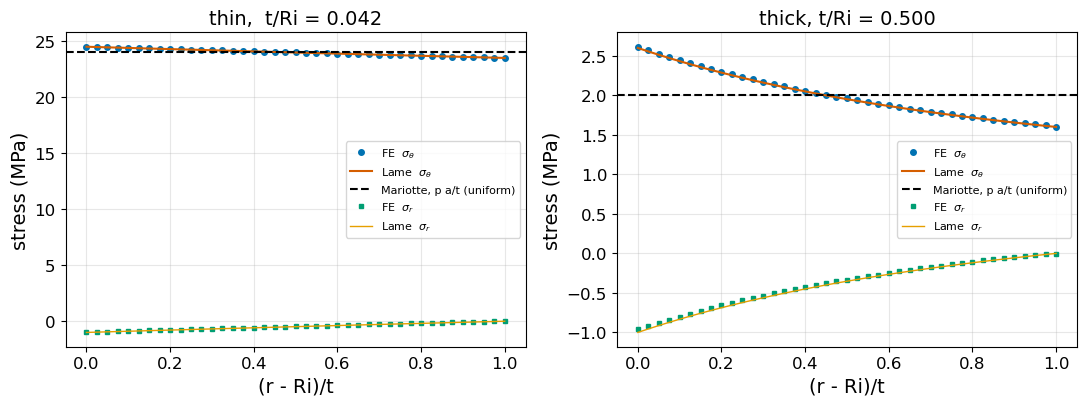

In [8]:
r2, s_rr2, s_tt2, s_zz2 = radial_profile(THICK)
a2, b2, p2 = r2.min(), r2.max(), 1.0e6
sr_L2, st_L2 = lame(r2, a2, b2, p2)
hoop_M2, _ = mariotte(a2, b2, p2)

print(f'thick cylinder: Ri = {a2:.3f} m, Ro = {b2:.3f} m, t/Ri = {(b2-a2)/a2:.3f}')
print(f'\n  FE hoop, inner wall = {s_tt2[0]/1e6:7.3f} MPa')
print(f'  Lame,   inner wall  = {st_L2[0]/1e6:7.3f} MPa'
      f'   -> FE-vs-Lame error {100*abs(st_L2[0]-s_tt2[0])/abs(st_L2[0]):.2f} %')
print(f'  FE hoop, average    = {np.trapezoid(s_tt2, r2)/(b2 - a2)/1e6:7.3f} MPa')
print(f'  Mariotte, p a/t     = {hoop_M2/1e6:7.3f} MPa'
      f'   -> error at the inner wall {100*abs(hoop_M2-s_tt2[0])/abs(s_tt2[0]):.1f} %')
print(f'\n  hoop varies across the wall by a factor '
      f'{s_tt2[0]/s_tt2[-1]:.2f} while Mariotte assumes a constant profile')

fig, ax = plt.subplots(1, 2)
for k, (rr, srr, stt, aa, bb, ttl) in enumerate([
        (r,  s_rr,  s_tt,  a_t, b_t, f'thin,  t/Ri = {(b_t-a_t)/a_t:.3f}'),
        (r2, s_rr2, s_tt2, a2,  b2,  f'thick, t/Ri = {(b2-a2)/a2:.3f}')]):
    sL, tL = lame(rr, aa, bb, 1.0e6)
    hM, _ = mariotte(aa, bb, 1.0e6)
    x = (rr - aa)/(bb - aa)
    ax[k].plot(x, stt/1e6, 'o', ms=4, label=r'FE  $\sigma_\theta$')
    ax[k].plot(x, tL/1e6, '-', label=r'Lame  $\sigma_\theta$')
    ax[k].axhline(hM/1e6, ls='--', c='k', label='Mariotte, p a/t (uniform)')
    ax[k].plot(x, srr/1e6, 's', ms=3, label=r'FE  $\sigma_r$')
    ax[k].plot(x, sL/1e6, '-', lw=1, label=r'Lame  $\sigma_r$')
    ax[k].set_xlabel('(r - Ri)/t'); ax[k].set_ylabel('stress (MPa)')
    ax[k].set_title(ttl); ax[k].legend(fontsize=8)
plt.tight_layout(); plt.show()


---
## 4. So where is the boundary?

Textbooks say "thin if $t/a < 1/10$" (sometimes, also $t/a< 1/20$). Those are (good) conventions, not physics.
The honest way to answer is to compute the error you are accepting, which you can now
do, because you have the exact solution.

The cell below sweeps $t/a$ and prints the peak and the average of the Lamé hoop stress
next to $pa/t$ and $pa/t + p/2$. No FE needed: Lamé *is* the exact answer for this problem.


In [9]:
# The exact average hoop stress, from radial equilibrium (see the note below)
def hoop_mean_exact(a, b, p):
    return p*a/(b - a)

print('  t/a    Lame peak   Lame avg      p*a/t   p*a/t + p/2')
for ratio in [0.05, 0.10, 0.20, 0.33, 0.50, 1.00]:
    aa = 1.0; bb = aa*(1 + ratio)
    rr = np.linspace(aa, bb, 200001)
    _, stt = lame(rr, aa, bb, 1.0e6)
    peak = stt[0]/1e6
    mean = np.trapezoid(stt, rr)/(bb - aa)/1e6
    m_in, _ = mariotte(aa, bb, 1.0e6)
    print(f'  {ratio:5.2f}  {peak:9.4f}  {mean:9.4f}  {m_in/1e6:9.4f}  {m_in/1e6 + 0.5:11.4f}')

print('\n  p*a/t (Mariotte) reproduces the AVERAGE hoop stress exactly, at every thickness.')
print('  p*a/t + p/2 is the membrane stress intensity of NB-3324.1, not a hoop stress.')
print('\nCheck the identity directly:')
for ratio in [0.05, 0.5, 1.0]:
    aa = 1.0; bb = aa*(1+ratio)
    rr = np.linspace(aa, bb, 200001)
    _, stt = lame(rr, aa, bb, 1.0e6)
    mean = np.trapezoid(stt, rr)/(bb-aa)
    print(f'   t/a = {ratio:4.2f}:  avg(Lame) - p*a/t = '
          f'{(mean - hoop_mean_exact(aa, bb, 1.0e6))/1e6:+.2e} MPa')


  t/a    Lame peak   Lame avg      p*a/t   p*a/t + p/2
   0.05    20.5122    20.0000    20.0000      20.5000
   0.10    10.5238    10.0000    10.0000      10.5000
   0.20     5.5455     5.0000     5.0000       5.5000
   0.33     3.6011     3.0303     3.0303       3.5303
   0.50     2.6000     2.0000     2.0000       2.5000
   1.00     1.6667     1.0000     1.0000       1.5000

  p*a/t (Mariotte) reproduces the AVERAGE hoop stress exactly, at every thickness.
  p*a/t + p/2 is the membrane stress intensity of NB-3324.1, not a hoop stress.

Check the identity directly:
   t/a = 0.05:  avg(Lame) - p*a/t = +3.17e-13 MPa
   t/a = 0.50:  avg(Lame) - p*a/t = +2.64e-12 MPa
   t/a = 1.00:  avg(Lame) - p*a/t = +4.86e-12 MPa


### What the sweep actually says

**$pa/t$ is not an approximation: it is the exact average hoop stress.**
It comes from a force balance on half the cylinder. Cut it along a diameter and take a
half-ring of unit height. The pressure on its bore pushes it outward with a resultant
$\int_0^\pi p\sin\theta\ a\ d\theta = 2pa$, the pressure times the projected width $2a$. The two
cut faces hold it back, each with $\int_a^b \sigma_\theta\ dr$. So $\int_a^b \sigma_\theta\ dr = pa$,
whatever the distribution of $\sigma_\theta$. The same integral follows from radial equilibrium in
axisymmetry, $\sigma_\theta = \dfrac{d}{dr}(r\sigma_r)$:

$$\int_a^b \sigma_\theta\ dr = \Big[r\ \sigma_r\Big]_a^b = b\cdot 0 - a\cdot(-p) = p\ a
\qquad\Longrightarrow\qquad
\bar\sigma_\theta = \frac{p\ a}{t}\quad\text{exactly, for any wall thickness.}$$

**So what is the thin-shell approximation actually approximating?** Not the average, the
average is exact. It is approximating the *distribution*: it claims $\sigma_\theta$ is
**uniform**, so that the average and the peak coincide. That claim fails as the wall thickens,
and the sweep shows how fast: the peak exceeds the average by about 3% at $t/a = 0.05$, by 30% at
$t/a = 0.5$.

**And the last column?** $pa/t + p/2$ is what NB-3324.1 limits, the membrane stress intensity
$\bar\sigma_\theta - \bar\sigma_r$. For a thin wall it is also about the hoop peak, so a thickness
sized with the Code keeps the peak near $S_m$.

**Which one do you need?** For a preliminary thickness from a force balance, the average is the honest quantity and $pa/t$ gives it exactly. The ASME primary-membrane check, $P_m \le S_m$, also works on averages: the stress intensity of the stresses averaged through the wall. The peak at the bore is a different question. It tells you how far Mariotte is from Lamé, and it is the stress that matters for fatigue. There the uniform assumption fails, and you need Lamé.

Note finally the **sign**: $pa/t$ sits below the hoop peak, and $pa/t + p/2$ below the stress
intensity at the bore, so neither is conservative if you use it for a peak check.


**Q1.** Prove that $\bar\sigma_\theta = pa/t$ exactly, starting from radial equilibrium
$d\sigma_r/dr + (\sigma_r-\sigma_\theta)/r = 0$ and the two traction-free/pressurised
boundary conditions. Where, if anywhere, did you assume the wall was thin?

**Q2.** Given Q1, state precisely what the thin-shell approximation approximates. Then
say which quantity, average or peak, your preliminary thickness calculation needs, which
one the ASME membrane check $P_m \le S_m$ uses, and where the peak does matter.


---
## 5. The other pressure, which can be the one that sizes the wall

Everything so far sized the wall against **strength**: pick $t$ so that the membrane stress stays under $S_m$. That is the right question when the pressure is on the *inside*.

Turn the pressure around and the question changes completely. A shell squeezed from outside can collapse **while still elastic**, because the round shape stops being stable, the same thing a slender column does under axial load, with the mode running around the circumference instead of along its length. On a slender shell, no stress check catches it: at the moment of collapse the material is nowhere near yielding.

Your vessel sees external pressure in real conditions (a depressurisation transient, a containment overpressure, a hydrostatic test done wrong), so it has **two** required thicknesses, and the wall has to satisfy both:

$$t = \max\big(t_{\text{internal}},\  t_{\text{external}}\big)$$

Two quantities matter, both functions of the slenderness $D/t$, where **$D$ is the
outer diameter** (Corradi, Ghielmetti & Luzzi 2008, the same convention as the ASME $D_o$):

$$q_E = \frac{2E}{1-\nu^2}\ \frac{1}{(D/t)\ [(D/t)-1]^2}
\qquad\text{(elastic collapse)}$$

$$q_0 = \frac{2S_y}{D/t}\left(1 + \frac{1}{2\ D/t}\right)
\qquad\text{(plastic collapse)}$$

with $E$ Young's modulus, $\nu$ Poisson's ratio and $S_y$ the yield strength.

$q_E$ is a *stability* limit and $q_0$ a *strength* one. Which is smaller decides how the shell fails, and, exactly as for a column, the answer depends on slenderness, not on the material alone.

In [10]:
# The two collapse pressures of a long, perfectly round tube: neutral steel at 290 degC
E, nu, Sy = 1.90e11, 0.30, 201e6     # Pa, -, Pa
def qE(Dt): return 2*(E/(1 - nu**2))/(Dt*(Dt - 1)**2)     # elastic collapse
def q0(Dt): return 2*Sy*(1 + 1/(2*Dt))/Dt                 # plastic collapse

print(f"{'D/t':>6}{'qE (MPa)':>11}{'q0 (MPa)':>11}   first to fail")
for Dt in (10, 20, 33, 66, 100):
    print(f"{Dt:6d}{qE(Dt)/1e6:11.2f}{q0(Dt)/1e6:11.2f}   "
          + ("plastic" if q0(Dt) < qE(Dt) else "elastic"))


   D/t   qE (MPa)   q0 (MPa)   first to fail
    10     515.53      42.21   plastic
    20      57.84      20.60   plastic
    33      12.36      12.37   elastic
    66       1.50       6.14   elastic
   100       0.43       4.04   elastic


The two curves cross near $D/t$ = 33. A slenderer shell buckles first, a stockier one collapses plastically. Find your own $D/t$ on this table.


### A perfect circle is not a vessel

The two formulas above hold for a mathematically round tube, and that is optimistic. A real cylinder is slightly oval, and an oval shell starts bending under external pressure immediately instead of only at the bifurcation, so it collapses earlier. This is the reason external-pressure design is done with a procedure rather than a formula.

The Code limits the ovality: **NB-4221.1** limits the out-of-roundness (the maximum difference between cross-sectional diameters) to the smaller of $(D+1250)/200$ and $D/100$, with $D$ the nominal inside diameter in mm. For external pressure, **NB-4221.2** adds a limit on the maximum deviation from the true circular form.

**The route of your report is ASME III NB-3133**, with the charts in the Annex of the assignment (Figs. 3 and 4). Another route exists, the procedure of Corradi, Ghielmetti and Luzzi (2008), which takes the ovality as an explicit input. It is not required.


Three things to take away, and the third is the one that gets forgotten.

- **Two sizings, one wall.** You size for internal pressure *and* for external pressure,
  and you build the thicker. Doing only the first is not a simplification, it is an
  omission, and it is not recoverable later, because everything downstream (the FE model
  in G5, the classification in G6) is built on the thickness you choose here.
- **The margin is different, and deliberately so.** Strength design works with $S_m$,
  already a fraction of yield. Buckling design carries a **factor 3 on collapse**, because
  the failure is imperfection-sensitive and a real shell is never round.
- **"External pressure does not govern" is a legitimate answer**, *with the numbers
  behind it*. State both thicknesses. The next person to read your report will change a
  design pressure, and those two numbers are what tells them whether they have to redo this.

---
## 6. Now your own vessel

**Two things before you start.** There is no thermal stress in this notebook, on purpose: the design thickness is limited by the primary stresses (NB-3221). Temperature enters here only through $S_m$ and the chart; the thermal stress comes in G5.

The neutral examples of these notebooks are not one vessel. The 13.7 mm of the neutral vessel in §1 is not the wall of G4, which takes 100 mm so that the gamma source has something to act on ($\mu t$ = 2.7, with $1/\mu$ the decay length of the gamma source). Your project has one wall: the one you carry forward from here is the one you use in G3, G4 and G5.

For your own vessel, write down:

1. A **tentative wall thickness** from **NB-3324.1**, with $S_m$ read at the tentative
   design temperature (Part 1, item 2), and how far it is from Lamé at
   your $t/a$: compute it (the cell below), not a textbook rule of thumb.
2. The **second thickness, from external pressure**, with **NB-3133** and the charts of the
   Annex ($T$ is the Code's symbol for the wall thickness, A and B the factors read from Figs. 3 and 4, $P_a$ the allowable external pressure): your design external pressure, $D_o/T$ and $L/D_o$, the factors A and B you
   read, and $P_a$. Take $L$ as NB-3133.2 defines it: without stiffening rings, the distance
   between the head tangent lines plus one third of the depth of each head. State what you
   assume for the heads, and the fabrication tolerance on the shape of the shell you assume
   (NB-4221), and whether it enters the chart procedure. Then **the wall you carry forward, which is the larger of the two**.

Point 2 is not optional bookkeeping. G5 builds a finite-element model on the thickness you
carry forward and G6 classifies its stresses: if the wall is wrong here, everything after
it is a correct calculation of the wrong vessel.

**And the wall is not final yet.** In G4 you compute the average metal
temperature through it, which is what the Code calls your design temperature; you then
re-read $S_m$ and the chart there and confirm this thickness or revise it. So keep this calculation in a form you can re-run with one number
changed.

**How far from Lamé, at your $t/a$.** The cell below takes your radii and pressure and prints
the Lamé peak next to $pa/t$ and next to $pa/t + p/2$: the last one is the number point 1 asks for.

In [11]:
# >>> CHANGE HERE: your inner and outer radius (m) and design pressure (Pa)
MY_a, MY_b, MY_p = 0.0, 0.0, 0.0
if MY_b > MY_a > 0:
    _, st = lame(np.array([MY_a]), MY_a, MY_b, MY_p)
    hM, _ = mariotte(MY_a, MY_b, MY_p)
    nb = hM + MY_p/2      # the membrane stress intensity NB-3324.1 limits
    print(f't/a = {(MY_b-MY_a)/MY_a:.3f}: Lame peak {st[0]/1e6:.1f} MPa, '
          f'p a/t {hM/1e6:.1f} MPa ({100*(st[0]/hM-1):+.1f} %), '
          f'NB-3324.1 p a/t + p/2 {nb/1e6:.1f} MPa ({100*(st[0]/nb-1):+.1f} %)')
else:
    print('write your radii and pressure above, then re-run this cell.')

write your radii and pressure above, then re-run this cell.


---

### For your report

**Both** thicknesses, internal and external pressure, with the tentative design temperature
they rest on, the model justification for each and the one you are carrying forward. Everything here is provisional by construction, and
saying so is part of the answer.

### Checklist

- Both thicknesses, with the $S_m$, the factors A and B and the $P_a$ behind them.
- The wall you carry forward.
- How far NB-3324.1 is from Lamé at your $t/a$, with the number from the cell of §6.
